In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("student_burnout_dropout_dataset_2.csv")
#df .info

In [3]:
#plt.figure(figsize=(12,6))
#sns.heatmap(df.isnull(), cbar=False)
#plt.title("Missing Data Heatmap")
#plt.show()

In [4]:
#Simple Fills
df['Gender'] = df['Gender'].fillna('Prefer Not to Say')
df['Part_Time_Job'] = df['Part_Time_Job'].fillna('No')

In [5]:
df.head()

,Student_ID,Age,Gender,Year_of_Study,Department,Residence_Type,Attendance_Percent,Study_Hours_Per_Day,Previous_GPA,Backlogs,...,Family_Income_Bracket,Financial_Stress_Score,Family_Support_Score,Stress_Level,Anxiety_Score,Motivation_Score,Peer_Pressure_Score,Counseling_Access,Burnout_Level,Dropout_Risk
0,STU00001,23,Female,2,Science,Hostel,93.0,4.1,7.13,2.0,...,Upper-Middle,5.5,10.0,4.0,NaN,7.0,NaN,No,Low,No
1,STU00002,20,Female,4,Engineering,Day Scholar,94.3,0.0,10.00,0.0,...,Low,3.7,4.0,5.5,5.1,9.3,2.8,Yes,Medium,Yes
2,STU00003,24,Male,2,Business,PG/Rented,61.2,2.6,8.02,0.0,...,Middle,4.8,8.1,9.0,5.2,5.7,5.4,No,High,Yes
3,STU00004,21,Female,4,Medicine,Hostel,66.9,3.1,5.34,1.0,...,Lower-Middle,7.0,6.6,2.8,4.2,5.1,3.9,No,High,Yes
4,STU00005,23,Female,1,Engineering,NaN,84.8,2.9,4.45,1.0,...,Lower-Middle,1.3,7.3,0.9,6.4,8.1,5.1,No,Low,No


I am using Family Income Bracket, Part time Job, Financial Stress Score and Family support score column to find means that we could use to fill in missing gaps for students who share a similar traits.

In [6]:
#Use part-time job + financial stress + family support
df['Family_Income_Bracket'] = df.groupby(['Part_Time_Job'])['Family_Income_Bracket'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else df['Family_Income_Bracket'].mode()[0])
)

#Use income + part-time job + family support
df['Financial_Stress_Score'] = df.groupby(['Family_Income_Bracket', 'Part_Time_Job'])['Financial_Stress_Score'].transform(
    lambda x: x.fillna(x.mean())
)

#Use income + part-time job + financial stress
df['Family_Support_Score'] = df.groupby(['Family_Income_Bracket', 'Part_Time_Job'])['Family_Support_Score'].transform(
    lambda x: x.fillna(x.mean())
)

In [7]:
#plt.figure(figsize=(12,6))
#sns.heatmap(df.isnull(), cbar=False)
#plt.title("Missing Data Heatmap")
#plt.show()

I then use previous GPA, Study hours per day and Attendance to fill the gaps in academic performance.

In [8]:
# GPA + Study Hours
df['Attendance_Percent'] = df.groupby(['Previous_GPA', 'Study_Hours_Per_Day'])['Attendance_Percent'].transform(
    lambda x: x.fillna(x.mean())
)

# GPA + Attendance
df['Study_Hours_Per_Day'] = df.groupby(['Previous_GPA', 'Attendance_Percent'])['Study_Hours_Per_Day'].transform(
    lambda x: x.fillna(x.mean())
)

# Attendance + Study hours 
df['Previous_GPA'] = df.groupby(['Attendance_Percent', 'Study_Hours_Per_Day'])['Previous_GPA'].transform(
    lambda x: x.fillna(x.mean())
)

#using the median to fill in any gaps
df['Attendance_Percent'] = df['Attendance_Percent'].fillna(df['Attendance_Percent'].median())
df['Study_Hours_Per_Day'] = df['Study_Hours_Per_Day'].fillna(df['Study_Hours_Per_Day'].median())
df['Previous_GPA'] = df['Previous_GPA'].fillna(df['Previous_GPA'].median())


In [9]:
#plt.figure(figsize=(12,6))
#sns.heatmap(df.isnull(), cbar=False)
#plt.title("Missing Data Heatmap")
#plt.show()

Missing Data May Not Be Random
Some students skip certain questions for specific reasons (low attendance, high stress, poor performance). This means missing values may be Missing Not At Random (MNAR). MNAR limits how accurately any imputation can reconstruct true behavior.

I used data from GPA and Attendance to fill in missing values for Backlogs. I used other methods as well until a few missing data remained in which i used the median to fill the final gaps. 

In [10]:
df['Backlogs'] = df.groupby(['Previous_GPA', 'Attendance_Percent'])['Backlogs'].transform(
    lambda x: x.fillna(x.mean())
)

df['Backlogs'] = df.groupby(['Previous_GPA', 'Study_Hours_Per_Day'])['Backlogs'].transform(
    lambda x: x.fillna(x.mean())
)

df['Backlogs'] = df.groupby('Attendance_Percent')['Backlogs'].transform(
    lambda x: x.fillna(x.mean())
)

df['Backlogs'] = df['Backlogs'].fillna(df['Backlogs'].median())

In [11]:
#plt.figure(figsize=(12,6))
#sns.heatmap(df.isnull(), cbar=False)
#plt.title("Missing Data Heatmap")
#plt.show()

Next i moved to cleaning Social life activities with Sleep hours, exercise, activity

In [12]:
# 1. Exercise + Sleep + Social Activity (strongest predictor combo)
df['Screen_Time_Hours'] = df.groupby(
    ['Exercise_Freq_Per_Week', 'Sleep_Hours', 'Social_Activity_Score']
)['Screen_Time_Hours'].transform(
    lambda x: x.fillna(x.mean())
)

# 2. Exercise + Sleep (fallback)
df['Screen_Time_Hours'] = df.groupby(
    ['Exercise_Freq_Per_Week', 'Sleep_Hours']
)['Screen_Time_Hours'].transform(
    lambda x: x.fillna(x.mean())
)

# 3. Exercise + Social Activity (fallback)
df['Screen_Time_Hours'] = df.groupby(
    ['Exercise_Freq_Per_Week', 'Social_Activity_Score']
)['Screen_Time_Hours'].transform(
    lambda x: x.fillna(x.mean())
)

# 4. Sleep alone (fallback)
df['Screen_Time_Hours'] = df.groupby('Sleep_Hours')['Screen_Time_Hours'].transform(
    lambda x: x.fillna(x.mean())
)

# 5. Final fallback
df['Screen_Time_Hours'] = df['Screen_Time_Hours'].fillna(df['Screen_Time_Hours'].median())

In [13]:
#plt.figure(figsize=(12,6))
#sns.heatmap(df.isnull(), cbar=False)
#plt.title("Missing Data Heatmap")
#plt.show()

In [14]:
# Screen Time + Sleep + Exercise
df['Social_Activity_Score'] = df.groupby(
    ['Screen_Time_Hours', 'Sleep_Hours', 'Exercise_Freq_Per_Week']
)['Social_Activity_Score'].transform(
    lambda x: x.fillna(x.mean())
)

# Screen Time + Exercise (fallback)
df['Social_Activity_Score'] = df.groupby(
    ['Screen_Time_Hours', 'Exercise_Freq_Per_Week']
)['Social_Activity_Score'].transform(
    lambda x: x.fillna(x.mean())
)

# Sleep alone (fallback)
df['Social_Activity_Score'] = df.groupby('Sleep_Hours')['Social_Activity_Score'].transform(
    lambda x: x.fillna(x.mean())
)

df['Social_Activity_Score'] = df['Social_Activity_Score'].fillna(df['Social_Activity_Score'].median())

In [15]:
# Social Activity + Exercise + Screen Time
df['Sleep_Hours'] = df.groupby(
    ['Social_Activity_Score', 'Exercise_Freq_Per_Week', 'Screen_Time_Hours']
)['Sleep_Hours'].transform(
    lambda x: x.fillna(x.mean())
)

# Social Activity + Exercise (fallback)
df['Sleep_Hours'] = df.groupby(
    ['Social_Activity_Score', 'Exercise_Freq_Per_Week']
)['Sleep_Hours'].transform(
    lambda x: x.fillna(x.mean())
)

# Screen Time alone (fallback)
df['Sleep_Hours'] = df.groupby('Screen_Time_Hours')['Sleep_Hours'].transform(
    lambda x: x.fillna(x.mean())
)

# Final fallback
df['Sleep_Hours'] = df['Sleep_Hours'].fillna(df['Sleep_Hours'].median())

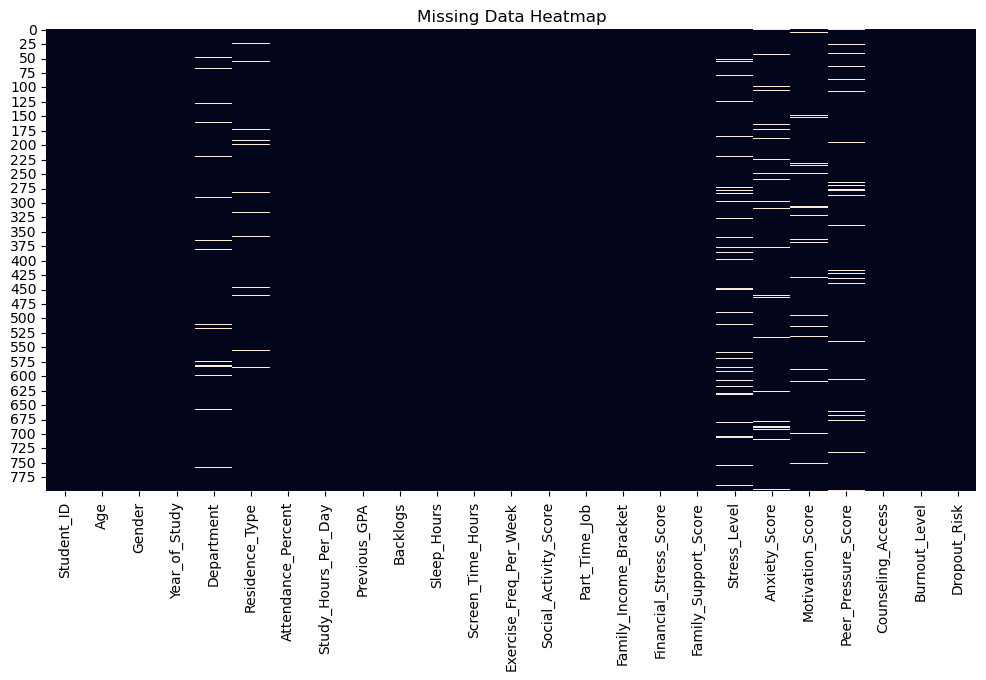

In [16]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Data Heatmap")
plt.show()

So here i am making a copy of the dataset. sicne i want to round the numbers of the cleaned data set and bin them so as to get all the facotrs that can cause stress and calculate the missing stress values. 

In [ ]:
for col in df.columns:
    print(col, df[col].unique())
    

In [36]:
df_numeric = df.select_dtypes(include=['float64', 'int64'])

In [38]:
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=5)
df_numeric_imputed = imputer.fit_transform(df_numeric)

In [39]:
df['Stress_Level'] = df_numeric_imputed[:, df_numeric.columns.get_loc('Stress_Level')]

In [42]:
#plt.figure(figsize=(12,6))
#sns.heatmap(df.isnull(), cbar=False)
#plt.title("Missing Data Heatmap")
#plt.show()

In [41]:
df['Motivation_Score'] = df.groupby(
    ['Stress_Level', 'Burnout_Level', 'Counseling_Access', 'Dropout_Risk']
)['Motivation_Score'].transform(lambda x: x.fillna(x.mean()))

df['Motivation_Score'] = df.groupby(
    ['Burnout_Level', 'Dropout_Risk']
)['Motivation_Score'].transform(lambda x: x.fillna(x.mean()))

df['Motivation_Score'] = df['Motivation_Score'].fillna(df['Motivation_Score'].median())

In [43]:
df['Peer_Pressure_Score'] = df.groupby(
    ['Stress_Level', 'Motivation_Score', 'Burnout_Level', 'Counseling_Access', 'Dropout_Risk']
)['Peer_Pressure_Score'].transform(lambda x: x.fillna(x.mean()))

df['Peer_Pressure_Score'] = df.groupby(
    ['Burnout_Level', 'Counseling_Access']
)['Peer_Pressure_Score'].transform(lambda x: x.fillna(x.mean()))

df['Peer_Pressure_Score'] = df['Peer_Pressure_Score'].fillna(df['Peer_Pressure_Score'].median())

In [44]:
df['Anxiety_Score'] = df.groupby(
    ['Stress_Level', 'Motivation_Score', 'Peer_Pressure_Score',
     'Burnout_Level', 'Counseling_Access', 'Dropout_Risk']
)['Anxiety_Score'].transform(lambda x: x.fillna(x.mean()))

df['Anxiety_Score'] = df.groupby(
    ['Burnout_Level', 'Counseling_Access']
)['Anxiety_Score'].transform(lambda x: x.fillna(x.mean()))

df['Anxiety_Score'] = df['Anxiety_Score'].fillna(df['Anxiety_Score'].median())

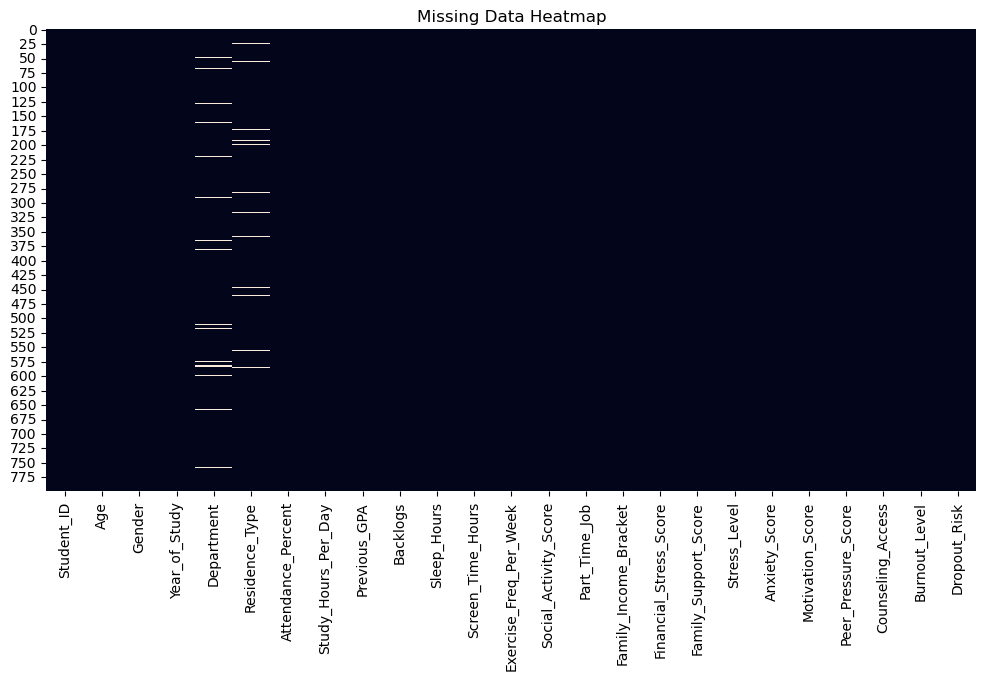

In [45]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Data Heatmap")
plt.show()

In [46]:
df.to_csv("CleanedBurnoutData.csv", index=False)
